In [57]:
import pandas as pd
import math
import random
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import numpy as np

df = pd.read_csv("seeds_data.csv")

print(df.head())
print(df.shape)

   Feature_1  Feature_2  Feature_3  Feature_4  Feature_5  Feature_6  \
0      15.26      14.84     0.8710      5.763      3.312      2.221   
1      14.88      14.57     0.8811      5.554      3.333      1.018   
2      14.29      14.09     0.9050      5.291      3.337      2.699   
3      13.84      13.94     0.8955      5.324      3.379      2.259   
4      16.14      14.99     0.9034      5.658      3.562      1.355   

   Feature_7  Class  
0      5.220      1  
1      4.956      1  
2      4.825      1  
3      4.805      1  
4      5.175      1  
(210, 8)


In [58]:
#separating the target from the features
actual_labels = df["Class"]
X = df.drop(columns=["Class"])

#scaling (z-score normalization)
X_scaled = StandardScaler().fit_transform(X)

In [59]:
# Calculate distance between two points
def distance(a, b):
    total = 0

    for i in range(len(a)):
        total += (a[i] - b[i]) ** 2

    return math.sqrt(total)


# K-Means algorithm
def kmeans(X, k):
    random.seed(42)

    centers = [list(p) for p in random.sample(list(X), k)]
    labels = [0] * len(X)

    for iteration in range(100):

        # Assign each point to its nearest center
        for i in range(len(X)):
            distances = []

            for center in centers:
                distances.append(distance(X[i], center))

            labels[i] = distances.index(min(distances))

        # Calculate new centers
        new_centers = []

        for cluster in range(k):
            points = []

            for i in range(len(X)):
                if labels[i] == cluster:
                    points.append(X[i])

            if len(points) == 0:
                new_centers.append(centers[cluster])
            else:
                center = []

                for j in range(len(X[0])):
                    average = sum(point[j] for point in points) / len(points)
                    center.append(average)

                new_centers.append(center)

        if new_centers == centers:
            break

        centers = new_centers

    # Calculate the total squared distance from each point to its center
    inertia = 0

    for i in range(len(X)):
        inertia += distance(X[i], centers[labels[i]]) ** 2

    return labels, centers, inertia

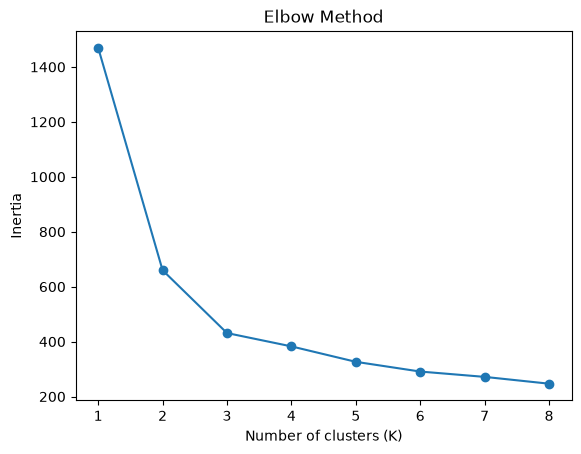

In [60]:
k_values = []
inertia_values = []

for k in range(1, 9):
    labels, centers, inertia = kmeans(X_scaled, k)

    k_values.append(k)
    inertia_values.append(inertia)

plt.plot(k_values, inertia_values, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [61]:
k = 3

kmeans_labels, centers, inertia = kmeans(X_scaled, k)

print("Final cluster centers:")

for center in centers:
    print(center)

Final cluster centers:
[np.float64(-1.0370524937828094), np.float64(-1.0113770018853214), np.float64(-0.9920352908558586), np.float64(-0.8938921541070514), np.float64(-1.1041537396622891), np.float64(0.7867723710039389), np.float64(-0.5972482405859858)]
[np.float64(-0.19329355991926897), np.float64(-0.22593176780544497), np.float64(0.4205540210446263), np.float64(-0.32042281173681353), np.float64(-0.0399218606745715), np.float64(-0.6886559710394614), np.float64(-0.6537174343729028)]
[np.float64(1.2265217311788064), np.float64(1.2357486257681067), np.float64(0.5327240035063897), np.float64(1.2199352425516874), np.float64(1.1303876829895563), np.float64(-0.04679181655633673), np.float64(1.2802065662183908)]


In [62]:
# DBSCAN algorithm
def dbscan(X, eps, min_samples):
    labels = [-1] * len(X)      # -1 means noise 
    cluster = 0

    def get_neighbors(i):
        result = []
        for j in range(len(X)):
            if distance(X[i], X[j]) <= eps:
                result.append(j)
        return result

    for i in range(len(X)):
        if labels[i] != -1:
            continue

        neighbors = get_neighbors(i)

        if len(neighbors) < min_samples:
            continue

        labels[i] = cluster

        # keeps expanding until there are no new points to check
        queue = neighbors
        while len(queue) > 0:
            j = queue.pop()

            if labels[j] != -1:
                continue

            labels[j] = cluster

            more_neighbors = get_neighbors(j)
            if len(more_neighbors) >= min_samples:
                queue.extend(more_neighbors)

        cluster += 1

    return labels

In [63]:
# Run DBSCAN
for eps in [0.4, 0.5, 0.6, 0.7, 0.8]:
    labels = dbscan(X_scaled, eps, 5)
    print(eps, "clusters:", len(set(labels) - {-1}), "noise:", labels.count(-1))

eps = 0.8
min_samples = 5

dbscan_labels = dbscan(X_scaled, eps, min_samples)

clusters = len(set(dbscan_labels) - {-1})
noise = dbscan_labels.count(-1)

print("DBSCAN clusters:", clusters)
print("Noise points:", noise)

0.4 clusters: 0 noise: 210
0.5 clusters: 1 noise: 205
0.6 clusters: 5 noise: 161
0.7 clusters: 7 noise: 78
0.8 clusters: 3 noise: 59
DBSCAN clusters: 3
Noise points: 59


In [64]:
# Compare clusters with actual labels
results = pd.DataFrame({
    "Actual Class": actual_labels,
    "K-Means": kmeans_labels,
    "DBSCAN": dbscan_labels
})

print(results.head(10))

print("\nActual Class vs DBSCAN:")
print(pd.crosstab(results["Actual Class"], results["DBSCAN"]))

   Actual Class  K-Means  DBSCAN
0             1        1       0
1             1        1       0
2             1        1       0
3             1        1       0
4             1        1      -1
5             1        1       0
6             1        1       0
7             1        1       0
8             1        2      -1
9             1        1      -1

Actual Class vs DBSCAN:
DBSCAN        -1   0   1   2
Actual Class                
1             22  48   0   0
2             26   0  15  29
3             11  59   0   0


In [65]:
# PCA for visualization
X_array = np.array(X_scaled)
X_centered = X_array - X_array.mean(axis=0)
covariance = np.cov(X_centered, rowvar=False)
values, vectors = np.linalg.eigh(covariance)
order = np.argsort(values)[::-1]
components = vectors[:, order[:2]]
X_pca = X_centered @ components

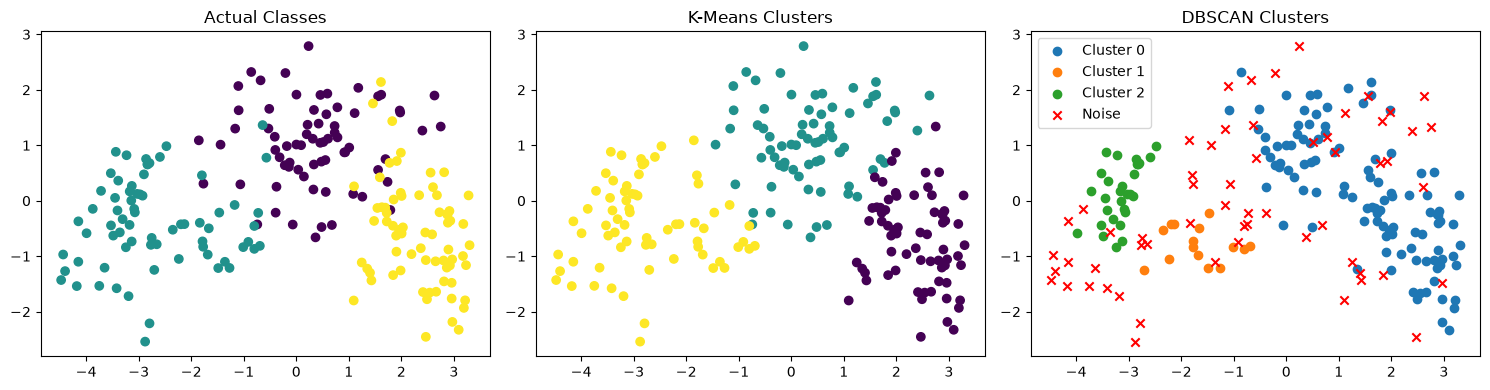

In [66]:
# Plot actual labels, K-Means and DBSCAN
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c=pd.factorize(actual_labels)[0])
plt.title("Actual Classes")

plt.subplot(1, 3, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c=kmeans_labels)
plt.title("K-Means Clusters")

plt.subplot(1, 3, 3)

for i in set(dbscan_labels):
    points = np.array(dbscan_labels) == i

    if i == -1:
        plt.scatter(X_pca[points, 0], X_pca[points, 1],
                    color="red", marker="x", label="Noise")
    else:
        plt.scatter(X_pca[points, 0], X_pca[points, 1],
                    label="Cluster " + str(i))

plt.title("DBSCAN Clusters")
plt.legend()

plt.tight_layout()
plt.show()


In [67]:
# Compare cluster assignments
print("\nActual Classes vs K-Means:")
print(pd.crosstab(actual_labels, kmeans_labels))

print("\nActual Classes vs DBSCAN:")
print(pd.crosstab(actual_labels, dbscan_labels))


Actual Classes vs K-Means:
col_0   0   1   2
Class            
1       3  65   2
2       0   3  67
3      65   5   0

Actual Classes vs DBSCAN:
col_0  -1   0   1   2
Class                
1      22  48   0   0
2      26   0  15  29
3      11  59   0   0
